<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week06Regresi/Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS06 - Regresi**<hr>
# **Praktikum 2**<hr>

## **Langkah 1: Mengimpor Library**

In [1]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## **Langkah 2: Mengimpor Dataset**

In [2]:
# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

## **Langkah 3: Feature Scaling**

In [3]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

## **Langkah 4: Fitting SVR ke Dataset**

In [4]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

## **Langkah 5: Visualisasi Hasil SVR**

/tmp/ipykernel_1870/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


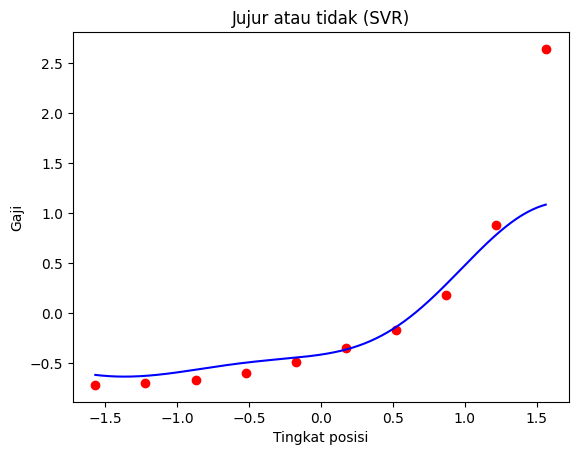

In [10]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

## **Langkah 6: Prediksi Hasil**

In [6]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

## **Langkah 7: Menampilkan Hasil**

In [7]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


## **8. Validasi Hasil**

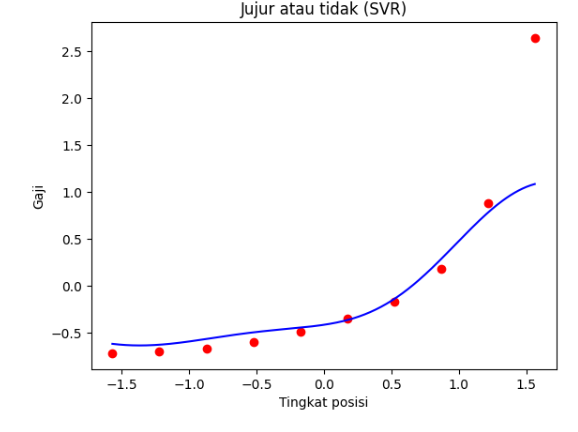

<br>

Screenshot 2026-10-21 022538.png

Hasil prediksi gaji untuk tingkat posisi 6.5 adalah 170.370,02. Ini menunjukkan bahwa proses feature scaling, pelatihan SVR dengan kernel RBF, dan pengembalian skala (inverse transform) sudah dilakukan dengan benar.

Pada grafik, titik merah adalah data asli dan garis biru adalah kurva prediksi SVR. Perlu diperhatikan bahwa kedua sumbu berada pada skala standar karena data sudah melalui StandardScaler. Kurva membentuk pola non-linear: kenaikan gaji landai pada tingkat posisi rendah, lalu naik tajam pada tingkat posisi tinggi, sesuai dengan pola data.

Meski begitu, kurva tidak mampu menjangkau titik data dengan tingkat posisi tertinggi (gaji sekitar 2,6 pada skala standar) dan berhenti di sekitar 1,1. Hal ini terjadi karena SVR dengan parameter default memperlakukan titik ekstrem tersebut sebagai outlier, sehingga model lebih memilih kurva yang halus daripada mengejar titik tersebut. Akibatnya, prediksi pada tingkat posisi sangat tinggi cenderung lebih rendah dari nilai sebenarnya.

## **Langkah 9: Evaluasi Model SVR**

In [8]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


Evaluasi model SVR menghasilkan MAE 0,223, MSE 0,248, RMSE 0,498, dan R² 0,752. Nilai ini dihitung pada data yang sudah melalui feature scaling dan pada data latih yang sama dengan yang dipakai untuk melatih model, sehingga belum menggambarkan performa pada data baru. R² sebesar 0,752 menunjukkan model menjelaskan sekitar 75% variasi gaji, dan sebagian error berasal dari titik dengan tingkat posisi tertinggi yang tidak terjangkau kurva.

## **Kesimpulan:**
Model SVR dengan kernel RBF mampu menangkap hubungan non-linear antara tingkat posisi dan gaji (R² 0,752 pada data latih), namun kurang baik pada titik ekstrem